In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/drive/MyDrive/Python/GitHub/goals-championship/csv/fotmob_match_stats.csv')
df.head(2)

,matchId,matchRound,homeTeamName,homeTeamid,awayTeamName,awayTeamid,home_goals,away_goals,ball_possession_home,ball_possession_away,...,ground_duels_won_home,ground_duels_won_away,aerial_won_home,aerial_won_away,dribbles_succeeded_home,dribbles_succeeded_away,yellow_cards_home,yellow_cards_away,red_cards_home,red_cards_away
0,5836754,1,Wolverhampton Wanderers,8602,Blackburn Rovers,8655,2,2,55,45,...,40 (56%),31 (44%),15 (48%),16 (52%),8 (44%),7 (41%),1,3,0,0
1,5836755,1,Bolton Wanderers,8559,Preston North End,8411,2,1,55,45,...,30 (48%),33 (52%),18 (49%),19 (51%),5 (38%),6 (55%),2,3,0,0


In [3]:
df = df.drop(37).reset_index(drop=True)
df = df.drop(46).reset_index(drop=True)

In [4]:
df.columns

Index(['matchId', 'matchRound', 'homeTeamName', 'homeTeamid', 'awayTeamName',
       'awayTeamid', 'home_goals', 'away_goals', 'ball_possession_home',
       'ball_possession_away', 'big_chances_home', 'big_chances_away',
       'big_chances_missed_home', 'big_chances_missed_away', 'fouls_home',
       'fouls_away', 'corners_home', 'corners_away', 'total_shots_home',
       'total_shots_away', 'shots_off_target_home', 'shots_off_target_away',
       'shots_on_target_home', 'shots_on_target_away', 'blocked_shots_home',
       'blocked_shots_away', 'hit_woodwork_home', 'hit_woodwork_away',
       'shots_inside_box_home', 'shots_inside_box_away',
       'shots_outside_box_home', 'shots_outside_box_away', 'xG_home',
       'xG_away', 'xG_open_play_home', 'xG_open_play_away', 'xG_set_play_home',
       'xG_set_play_away', 'xG_non_penalty_home', 'xG_non_penalty_away',
       'xGOT_home', 'xGOT_away', 'passes_home', 'passes_away',
       'accurate_passes_home', 'accurate_passes_away', 'own_ha

In [5]:
df.shape

(192, 82)

In [6]:
# filter by home goals
home_goals_df = df.groupby(by='homeTeamName')['home_goals'].sum().sort_values(ascending=False).reset_index()
home_goals_df.head()

,homeTeamName,home_goals
0,Southampton,22
1,Cardiff City,21
2,Middlesbrough,19
3,Birmingham City,19
4,West Ham United,19


In [7]:
# get the if of the match with most goals playing home
df.iloc[df['home_goals'].idxmax()]

,69
matchId,5836837
matchRound,7
homeTeamName,West Ham United
homeTeamid,8654
awayTeamName,Wrexham
...,...
dribbles_succeeded_away,6 (46%)
yellow_cards_home,1
yellow_cards_away,0
red_cards_home,0


In [8]:
# filter by away goals
away_goals_df = df.groupby(by='awayTeamName')['away_goals'].sum().sort_values(ascending=False).reset_index()
away_goals_df.head()

,awayTeamName,away_goals
0,West Ham United,19
1,Norwich City,19
2,Burnley,14
3,Wolverhampton Wanderers,13
4,Middlesbrough,13


In [9]:
# merge both DataFrames
goals_df = pd.merge(
    home_goals_df,
    away_goals_df,
    left_on='homeTeamName',
    right_on='awayTeamName',
    how='outer'
)

# create a single teamName column
goals_df['teamName'] = goals_df['homeTeamName'].combine_first(
    goals_df['awayTeamName']
)

# reorder
goals_df = goals_df[['teamName', 'home_goals', 'away_goals']]

# replace missing values with 0
goals_df[['home_goals', 'away_goals']] = goals_df[
    ['home_goals', 'away_goals']
].fillna(0)

goals_df.head()

,teamName,home_goals,away_goals
0,Birmingham City,19,9
1,Blackburn Rovers,14,10
2,Bolton Wanderers,10,11
3,Bristol City,4,12
4,Burnley,10,14


In [10]:
# sort values
goals_df.sort_values('home_goals', ascending=False)

,teamName,home_goals,away_goals
16,Southampton,22,9
5,Cardiff City,21,7
9,Middlesbrough,19,13
0,Birmingham City,19,9
21,West Ham United,19,19
14,Queens Park Rangers,16,9
22,Wolverhampton Wanderers,15,13
11,Norwich City,15,19
10,Millwall,15,8
1,Blackburn Rovers,14,10


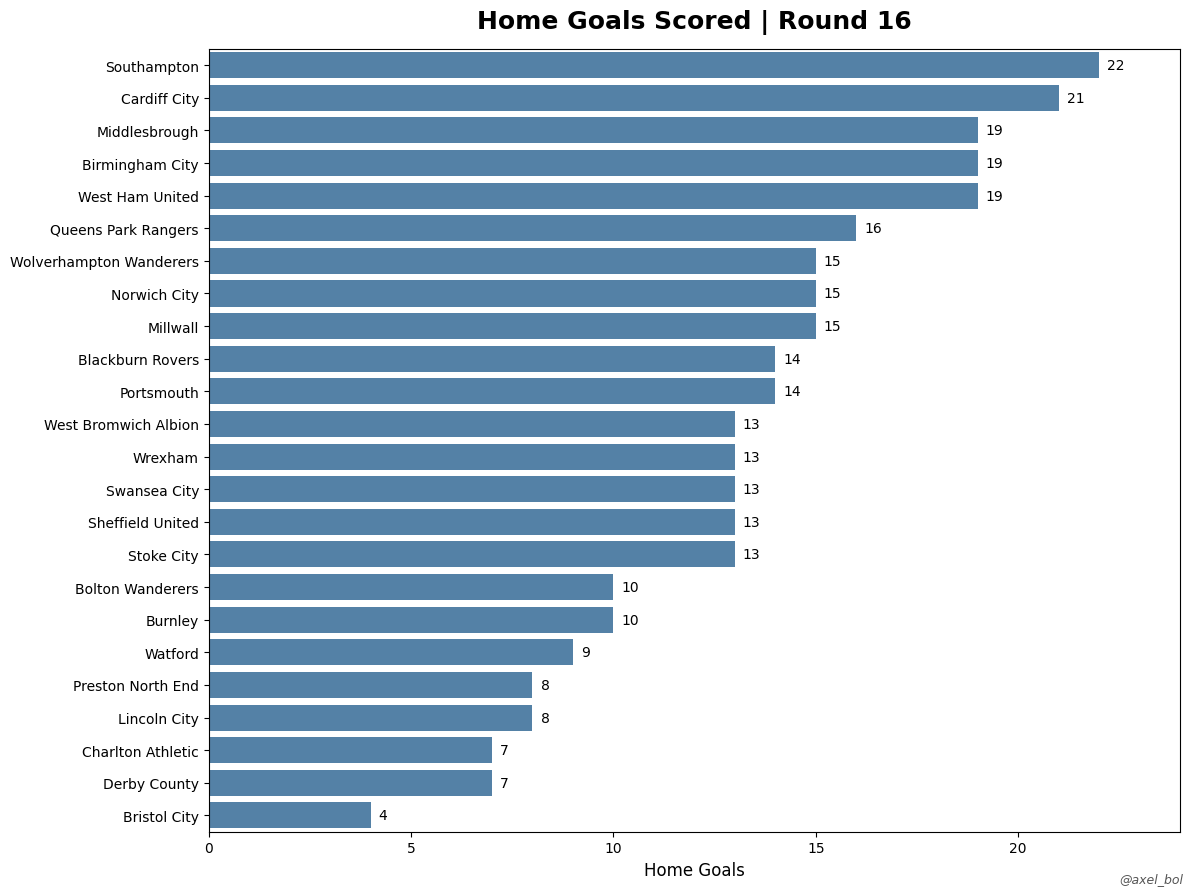

In [12]:
# home goals bar chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sort dataframe
home_df = goals_df.sort_values('home_goals', ascending=False)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=home_df,
    x='home_goals',
    y='teamName',
    color='steelblue'
)

plt.title('Home Goals Scored | Round 16', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Home Goals', fontsize=12)
plt.ylabel('')

# add values at the end of bars
for i, value in enumerate(home_df['home_goals']):
    plt.text(value + 0.2, i, str(value), va='center', fontsize=10)

plt.xlim(0, home_df['home_goals'].max() + 2)

plt.figtext(
    0.99, 0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#555555',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/homeGoalsScored.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=True)
plt.show()

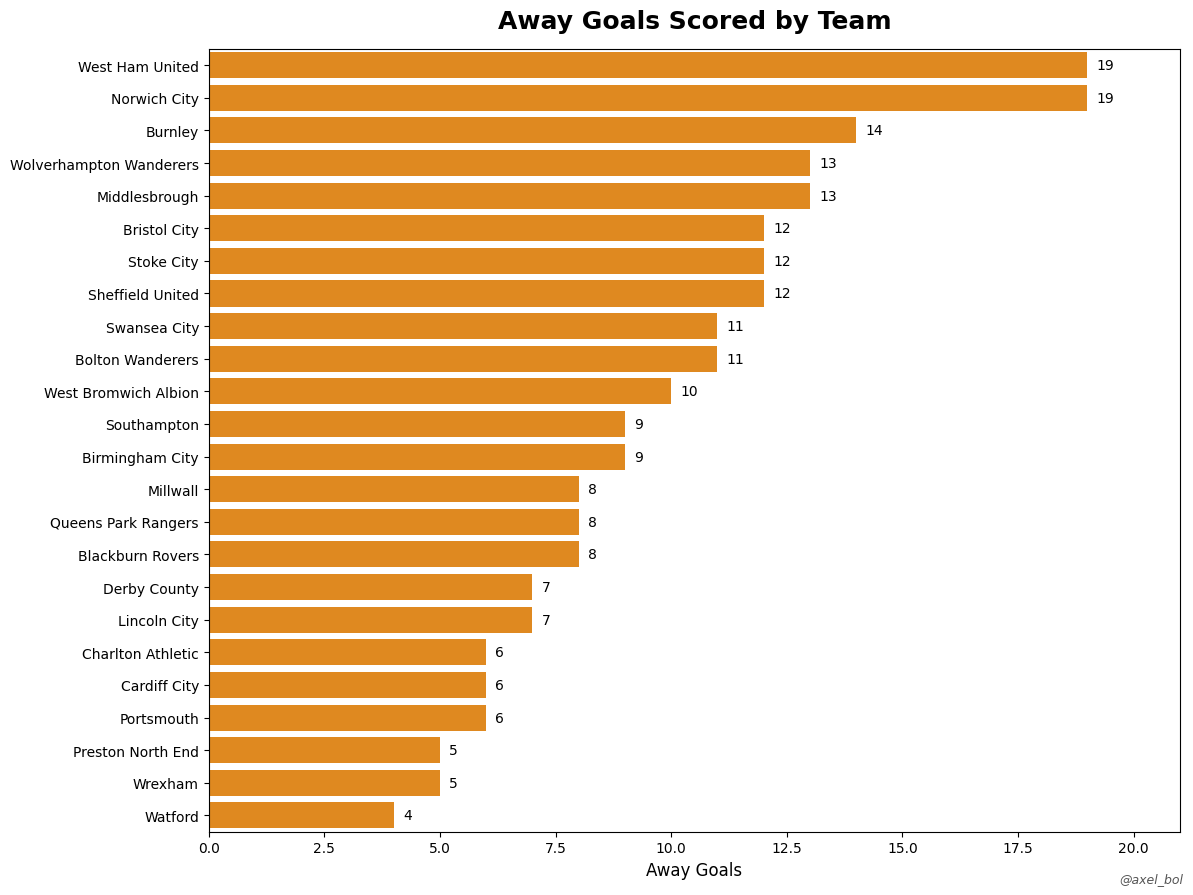

In [ ]:
# away goals bar chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sort dataframe
away_df = goals_df.sort_values('away_goals', ascending=False)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=away_df,
    x='away_goals',
    y='teamName',
    color='darkorange'
)

plt.title('Away Goals Scored by Team', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Away Goals', fontsize=12)
plt.ylabel('')

# Add values at the end of bars
for i, value in enumerate(away_df['away_goals']):
    plt.text(value + 0.2, i, str(value), va='center', fontsize=10)

plt.xlim(0, away_df['away_goals'].max() + 2)

plt.figtext(
    0.99, 0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#555555',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/awayGoalsScored.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=True)
plt.show()

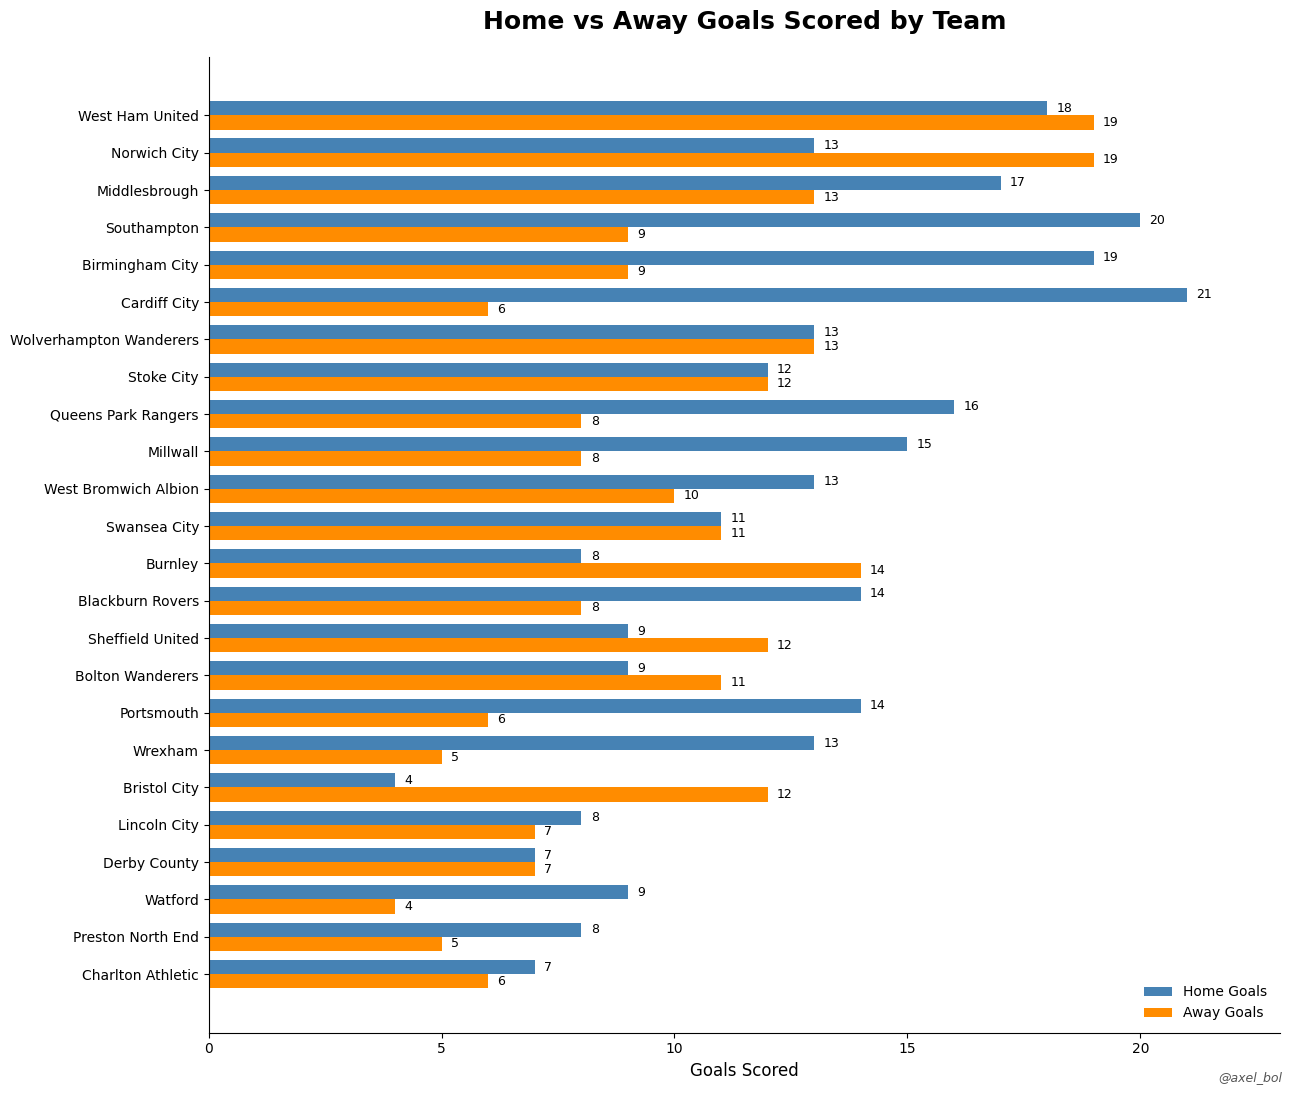

In [ ]:
# home vs away goals bar chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# sort by total goals
combined_df = goals_df.copy()

combined_df['total_goals'] = (
    combined_df['home_goals'] + combined_df['away_goals']
)

combined_df = combined_df.sort_values('total_goals', ascending=True)

y = np.arange(len(combined_df))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(13, 11))

# home goals
ax.barh(
    y + bar_height/2,
    combined_df['home_goals'],
    height=bar_height,
    label='Home Goals',
    color='steelblue'
)

# away goals
ax.barh(
    y - bar_height/2,
    combined_df['away_goals'],
    height=bar_height,
    label='Away Goals',
    color='darkorange'
)

# Add labels
for i, (home, away) in enumerate(
    zip(combined_df['home_goals'], combined_df['away_goals'])
):
    ax.text(home + 0.2, i + bar_height/2, str(home), va='center', fontsize=9)

    ax.text(away + 0.2, i - bar_height/2, str(away), va='center', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(combined_df['teamName'])

ax.set_title(
    'Home vs Away Goals Scored by Team',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Goals Scored', fontsize=12)
ax.set_ylabel('')

ax.legend(loc='lower right', frameon=False)

ax.set_xlim(0, combined_df[['home_goals', 'away_goals']].max().max() + 2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.figtext(
    0.99, 0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#555555',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/homeAwayGoalsScored.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=True)
plt.show()

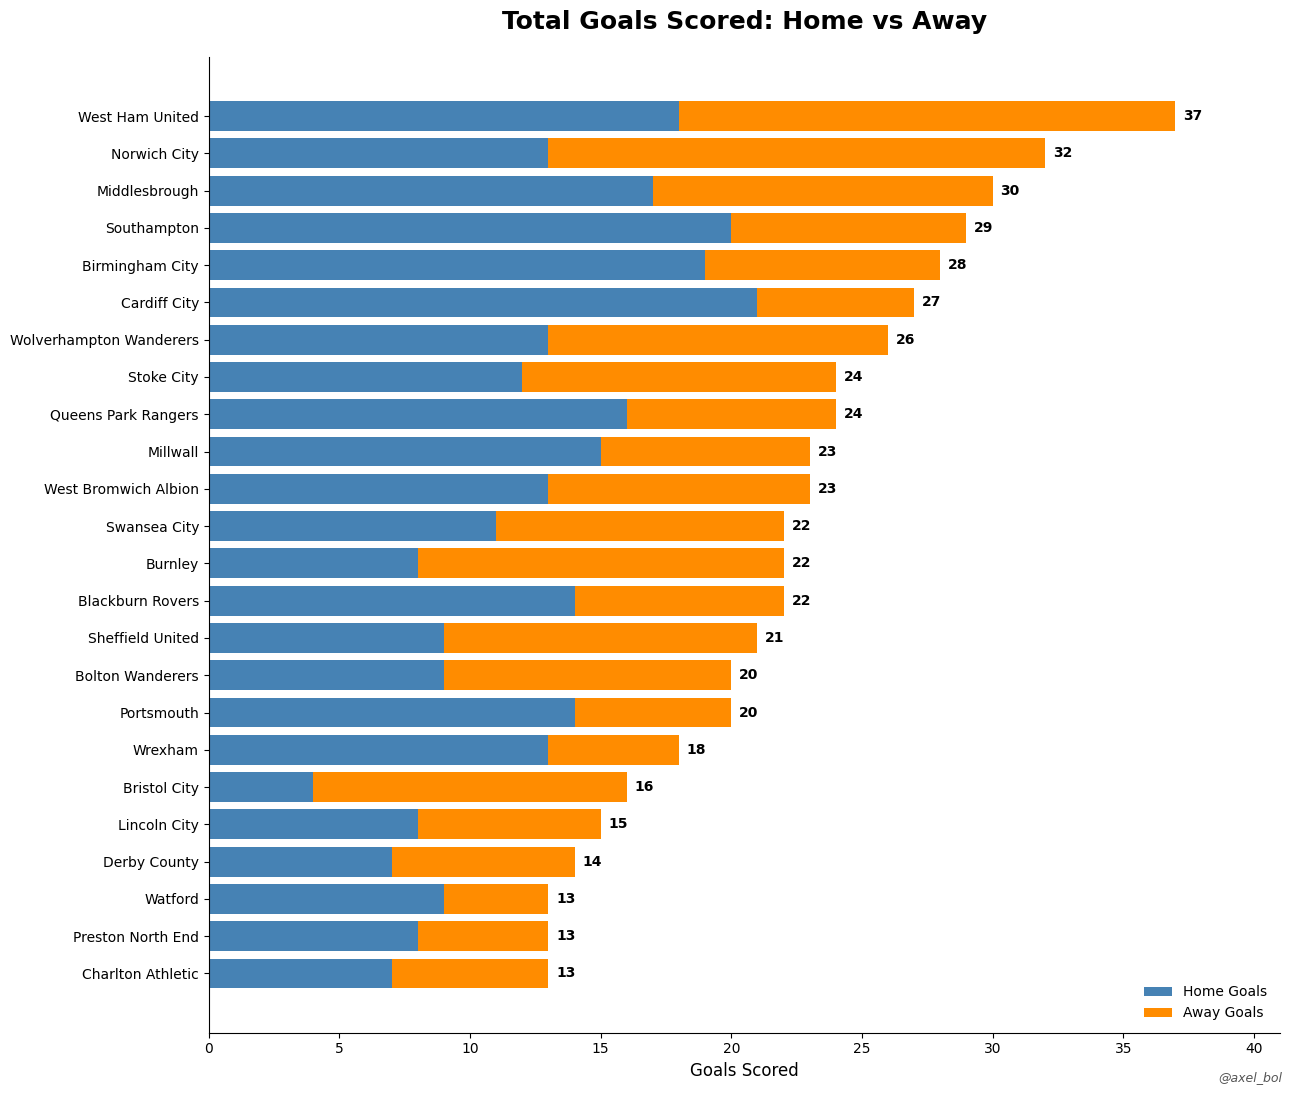

In [ ]:
# stack bar chart home & away
import matplotlib.pyplot as plt
import numpy as np

# sort by total goals
stacked_df = goals_df.copy()

stacked_df['total_goals'] = (
    stacked_df['home_goals'] + stacked_df['away_goals']
)

stacked_df = stacked_df.sort_values('total_goals', ascending=True)

fig, ax = plt.subplots(figsize=(13, 11))

# home goals
ax.barh(
    stacked_df['teamName'],
    stacked_df['home_goals'],
    color='steelblue',
    label='Home Goals'
)

# away goals (stacked on top of home goals)
ax.barh(
    stacked_df['teamName'],
    stacked_df['away_goals'],
    left=stacked_df['home_goals'],
    color='darkorange',
    label='Away Goals'
)

# add total goals at the end of each bar
for i, total in enumerate(stacked_df['total_goals']):
    ax.text(
        total + 0.3,
        i,
        str(total),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# styling
ax.set_title(
    'Total Goals Scored: Home vs Away',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Goals Scored', fontsize=12)
ax.set_ylabel('')

ax.legend(loc='lower right', frameon=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlim(0, stacked_df['total_goals'].max() + 4)

plt.figtext(
    0.99, 0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#555555',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/homeAwayGoalsScoredStacked.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=True)
plt.show()

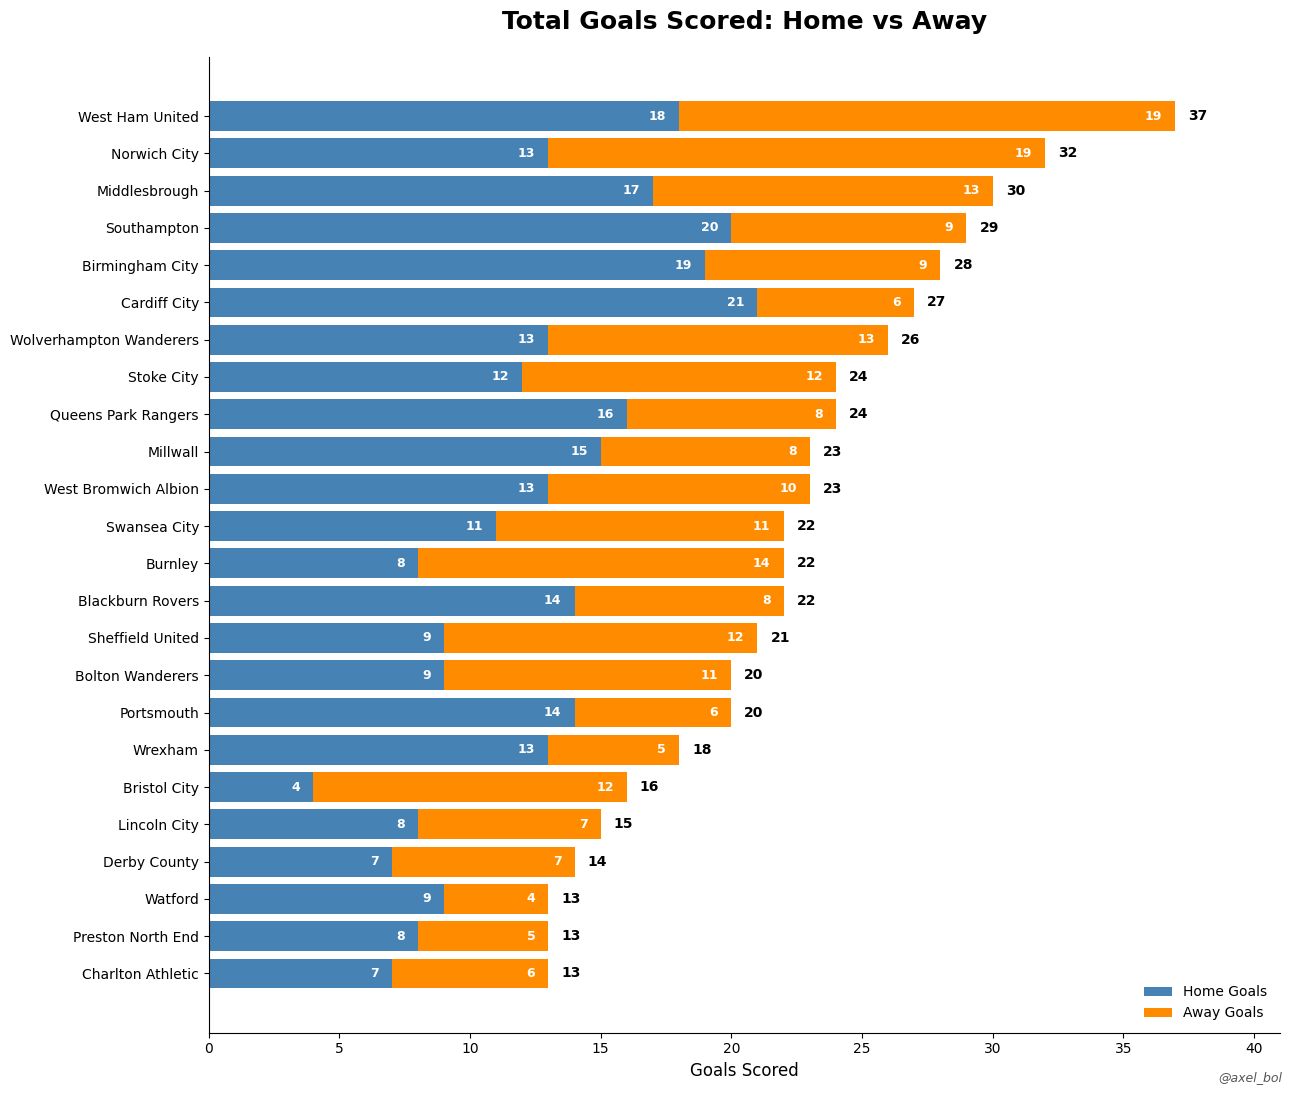

In [ ]:
# stack bar chart home & away w/ labels
import matplotlib.pyplot as plt
import numpy as np

# sort by total goals
stacked_df = goals_df.copy()

stacked_df['total_goals'] = (
    stacked_df['home_goals'] + stacked_df['away_goals']
)

stacked_df = stacked_df.sort_values('total_goals', ascending=True)

fig, ax = plt.subplots(figsize=(13, 11))

# home goals
ax.barh(
    stacked_df['teamName'],
    stacked_df['home_goals'],
    color='steelblue',
    label='Home Goals'
)

# away goals
ax.barh(
    stacked_df['teamName'],
    stacked_df['away_goals'],
    left=stacked_df['home_goals'],
    color='darkorange',
    label='Away Goals'
)

# add labels inside each segment + total outside
for i, row in enumerate(stacked_df.itertuples()):

    # home goals (inside blue segment)
    ax.text(
        row.home_goals - 0.5,
        i,
        str(row.home_goals),
        va='center',
        ha='right',
        fontsize=9,
        fontweight='bold',
        color='white'
    )

    # away goals (inside orange segment)
    ax.text(
        row.home_goals + row.away_goals - 0.5,
        i,
        str(row.away_goals),
        va='center',
        ha='right',
        fontsize=9,
        fontweight='bold',
        color='white'
    )

    # total goals (outside the bar)
    ax.text(
        row.total_goals + 0.5,
        i,
        str(row.total_goals),
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# styling
ax.set_title(
    'Total Goals Scored: Home vs Away',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Goals Scored', fontsize=12)
ax.set_ylabel('')

ax.legend(loc='lower right', frameon=False)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlim(0, stacked_df['total_goals'].max() + 4)

plt.figtext(
    0.99, 0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#555555',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/img/homeAwayGoalsScoredStackedLabel.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=True)
plt.show()